# 03 · Records, Fields and Lanes

**NHyDB 0.27.1 notebook series · v1**

The complete data model of NHyDB in one notebook: shapes and their 15 field types, extensions, the two lanes NL and NR, dense records and sparse cells, null values, deletion as a new state – and how to read many records at once. NHyDB is not just a new formula for classic tables: one address, several ways to use it.

> **Who is this for?** This notebook starts with a short introduction and continues with runnable examples. **New to NHyDB?** Read from top to bottom – every idea is introduced before it is used. **Already know the basics?** Skip the sections marked 📘 *Background* and jump to the experiments marked ▶. All cells run from top to bottom; optional deep dives are marked ⏩ *Advanced*.

**What you will learn**

* shapes, BASE fields and the **15 field types** – and what each costs on disk
* **extensions**: extra fields that only cost space where they are used
* the **two lanes**: the same `(R, u, v)` holds two independent cells
* **dense** records vs. **sparse** cells, **null** vs. missing, **deletion** as a new state
* reading many records with lazy iterators that skip gaps

**Recommended before:** [02 · From Mathematics to Stored Values](02_from_address_to_data_v1.ipynb).

### Setup

The next cell checks the environment and defines a few small plotting helpers used in
this notebook. It is collapsed because it is not about NHyDB itself – feel free to open
it. Every database in this notebook lives in a temporary folder that is removed at
the end.

In [1]:
import math
import os
import shutil
import sys
import tempfile

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle

import nhydb

# --- environment check ---------------------------------------------------------
EXPECTED = "0.27.1"
print(f"Python {sys.version.split()[0]} · nhydb {nhydb.ENGINE_VERSION} · "
      f"file format {nhydb.FILE_FORMAT_VERSION} · matplotlib {matplotlib.__version__}")
if nhydb.ENGINE_VERSION != EXPECTED:
    print(f"⚠ This notebook was written for NHyDB {EXPECTED}; results may differ.")

# --- a private temporary folder for all databases of this notebook --------------
WORKDIR = tempfile.mkdtemp(prefix="nhydb_notebook_")


def db_path(name):
    """Path of a new database file inside the temporary folder."""
    return os.path.join(WORKDIR, name)


def cleanup():
    shutil.rmtree(WORKDIR, ignore_errors=True)


def file_sizes(path):
    """Sizes of the files that belong to a database (bytes)."""
    folder, base = os.path.split(path)
    return {f: os.path.getsize(os.path.join(folder, f))
            for f in sorted(os.listdir(folder)) if f.startswith(base)}


# --- one visual language for the whole series -----------------------------------
# Layer A (mathematical address space) = blue tones, layer B (logical data model) =
# green, layer C (storage engine) = slate grey. Lanes and boundary points belong to A.
COLORS = {
    "A": "#1d4ed8", "A_light": "#dbeafe",
    "B": "#15803d", "B_light": "#dcfce7",
    "C": "#475569", "C_light": "#e2e8f0",
    "NL": "#2563eb", "NR": "#7c3aed",
    "GZ": "#dc2626", "N0": "#9ca3af",
    "attention": "#ea580c", "ok": "#16a34a", "bad": "#dc2626",
}
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 11,
})


def kind_of(n):
    """'NL', 'NR', 'GZ' or 'N0' for a natural number n >= 1 (computed by NHyDB)."""
    try:
        return nhydb.n_to_dynadron_address(n)["lane_name"]
    except nhydb.AddressError:
        return "GZ" if math.isqrt(n) ** 2 == n else "N0"


def group_of(n):
    """The group G whose interval [G(G-1), G(G+1)) contains n."""
    g = math.isqrt(n)
    return g + 1 if n - g * g >= g else g       # N0(g+1) and the NL cells of g+1 lie above g² + g − 1


KIND_LABEL = {"NL": "NL cell", "NR": "NR cell", "GZ": "GZ point (G²)", "N0": "N0 point (G·(G−1))"}


def plot_address_grid(ax, u_max, v_max, lane, highlight=(), annotate=True, title=None, values=None):
    """The (u, v) plane of realm 1 for one lane; every square shows its number N.

    Anti-diagonals u + v = G are the groups. ``highlight`` is a set of (u, v);
    ``values`` maps (u, v) to a short text shown under N (stored data).
    """
    import matplotlib.colors as mcolors
    base = COLORS[lane]
    cmap = mcolors.LinearSegmentedColormap.from_list(lane, ["#ffffff", base])
    highlight = set(highlight)
    g_top = u_max + v_max
    for u in range(1, u_max + 1):
        for v in range(1, v_max + 1):
            n = nhydb.dynadron_n(1, u, v, lane)
            g = u + v
            shade = 0.25 + 0.6 * (g - 2) / max(1, g_top - 2)
            ax.add_patch(Rectangle((u - 0.5, v - 0.5), 1, 1, facecolor=cmap(shade),
                                   edgecolor=COLORS["attention"] if (u, v) in highlight else "white",
                                   linewidth=2.6 if (u, v) in highlight else 0.8, zorder=2 if (u, v) in highlight else 1))
            if annotate:
                txt = str(n)
                if values and (u, v) in values:
                    txt += "\n" + str(values[(u, v)])
                ax.text(u, v, txt, ha="center", va="center", fontsize=7.5 if n < 1000 else 6.5,
                        color="white" if shade > 0.55 else "#111827", zorder=3)
    for g in range(2, g_top + 1):        # group diagonals u + v = G
        ax.plot([g - v_max - 0.5, g - 0.5], [v_max + 0.5, 0.5], color="#94a3b8", lw=0.4, zorder=0)
    ax.set_xlim(0.5, u_max + 0.5)
    ax.set_ylim(0.5, v_max + 0.5)
    ax.set_xticks(range(1, u_max + 1))
    ax.set_yticks(range(1, v_max + 1))
    ax.set_xlabel("u")
    ax.set_ylabel("v")
    ax.set_aspect("equal")
    ax.set_title(title or f"lane {lane}:  N = G² {'−' if lane == 'NL' else '+'} {'u' if lane == 'NL' else 'v'}",
                 color=base)

import pandas as pd

Python 3.14.5 · nhydb 0.27.1 · file format 0.16 · matplotlib 3.11.2


## 📘 Background: the vocabulary of the data model

| Term | Meaning | Where it lives |
|---|---|---|
| **cell** | one value at `(R, u, v, lane)` | layer A – it has a number `N` |
| **shape** | named, typed BASE fields `v = 1 … k` of a record | layer B (schema) |
| **record** | the cells `v = 1 … k` of one `u` (CLASSIC layout) | layer B |
| **extension** | a named, typed field at a `v` above the BASE fields | layer B, stored sparse |
| **lane** | NL (0) or NR (1) – two cells per `(R, u, v)` | layer A |
| **dense / sparse** | records written as blocks / single cells | layer C (storage) |

We use a small sensor-station example throughout: each station is one record.

## 1 · Shapes and the 15 field types

**Question:** Which kinds of values can a field hold – and what do they cost?

▶ **Run it:** one record with one field of **every** type, written and read back exactly.

In [2]:
ALL_TYPES = [("u8", 255), ("u16", 65535), ("u32", 4_000_000_000), ("u64", 2**64 - 1),
             ("i8", -128), ("i16", -30000), ("i32", -2**31), ("i64", -2**63),
             ("f32", 1.5), ("f64", 3.141592653589793), ("bool", True),
             ("varuint", 10**40), ("varint", -10**40), ("utf8", "Grüße ✓"), ("bytes", b"\x00\xff")]

PATH_T = db_path("types.nhydb")
with nhydb.create(PATH_T) as db:
    db.create_realm(1, "types")
    db.create_shape(1, 1, "all", [{"v": i + 1, "name": t, "type": t} for i, (t, _) in enumerate(ALL_TYPES)])
    db.create_classic_layout(1, 1, "all", shape_id=1)
    db.put_record(1, 1, {t: value for t, value in ALL_TYPES}, commit=True)
    back = db.get_record(1, 1)

pd.DataFrame([{"v": i + 1, "type": t, "code": nhydb.TYPE_CODES[t], "written": repr(val)[:24],
               "read back equal": back[t] == val} for i, (t, val) in enumerate(ALL_TYPES)]).set_index("v")

,type,code,written,read back equal
v,,,,
1,u8,1,255,True
2,u16,2,65535,True
3,u32,3,4000000000,True
4,u64,4,18446744073709551615,True
5,i8,5,-128,True
6,i16,6,-30000,True
7,i32,7,-2147483648,True
8,i64,8,-9223372036854775808,True
9,f32,9,1.5,True


In [3]:
assert len(nhydb.TYPE_CODES) == 15 and all(back[t] == val for t, val in ALL_TYPES)
try:
    with nhydb.open(PATH_T) as db:
        db.put_record(1, 2, {**{t: v for t, v in ALL_TYPES}, "u8": 256})
except ValueError as e:
    print("u8 = 256 rejected →", e)

u8 = 256 rejected → u8: 256 does not fit into u8


### What does a value cost?

▶ **Run it:** for each type we write **1000 records** with a single field into a fresh database
and measure how much the file grows. This is the real on-disk cost per record (value plus a
small per-record overhead), not a theoretical size.

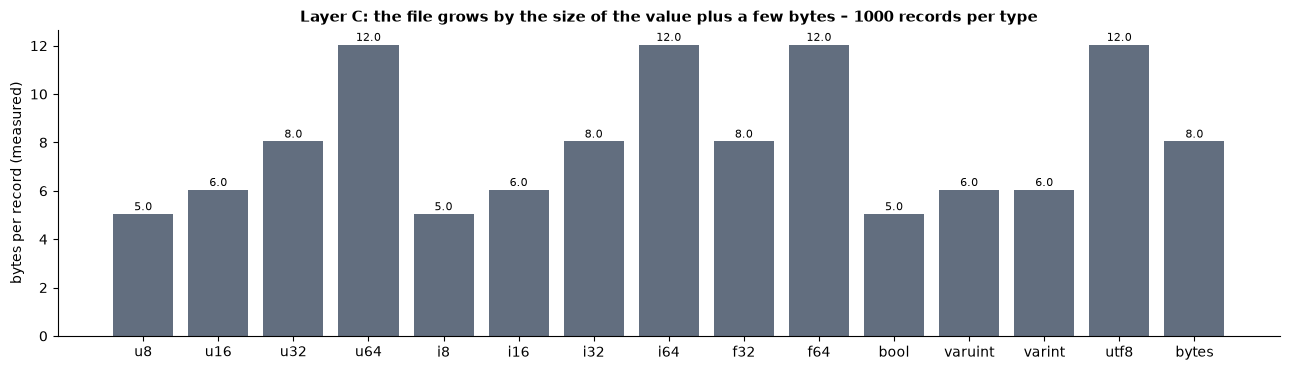

In [4]:
SAMPLE = {"u8": 200, "u16": 60000, "u32": 4_000_000_000, "u64": 2**64 - 1, "i8": -100, "i16": -30000,
          "i32": -2**31, "i64": -2**63, "f32": 1.5, "f64": 3.14159, "bool": True, "varuint": 300,
          "varint": -300, "utf8": "Grüße", "bytes": b"\x00\xff\x10"}
cost = []
for t, value in SAMPLE.items():
    p = db_path(f"cost_{t}.nhydb")
    with nhydb.create(p) as db:
        db.create_realm(1, "t")
        db.create_shape(1, 1, "s", [{"v": 1, "name": "x", "type": t}])
        db.create_classic_layout(1, 1, "c", shape_id=1)
        db.commit()
        before = os.path.getsize(p)
        db.put_dense_batch(1, 1, [[value]] * 1000, commit=True)
        cost.append({"type": t, "bytes per record": (os.path.getsize(p) - before) / 1000})
cost = pd.DataFrame(cost)

fig, ax = plt.subplots(figsize=(13, 3.8))
bars = ax.bar(cost["type"], cost["bytes per record"], color=COLORS["C"], alpha=0.85)
for b, val in zip(bars, cost["bytes per record"]):
    ax.text(b.get_x() + b.get_width() / 2, val + 0.15, f"{val:.1f}", ha="center", fontsize=8)
ax.set_ylabel("bytes per record (measured)")
ax.set_title("Layer C: the file grows by the size of the value plus a few bytes – 1000 records per type")
plt.tight_layout()
plt.show()

**What happened?** Fixed-width types cost their width (`u8` 1 byte, `f64` 8 bytes, …) plus about
4 bytes of per-record overhead in a dense block. `varuint`/`varint` grow with the value (300 needs
two bytes), `utf8` and `bytes` with their length. `utf8` text `"Grüße"` is 7 bytes because the
umlauts need two bytes each in UTF-8.

## 2 · Records, extensions and the BASE boundary

**Question:** How do I add a field that only a few records need?

**Minimal explanation:** BASE fields (the shape) are written for every record in dense blocks.
**Extensions** are named fields at a higher `v`; they are stored *sparse*, so only records that
have a value pay for it. `base_reserve_to` keeps a `v` range free for future BASE fields.

In [5]:
PATH = db_path("stations.nhydb")
with nhydb.create(PATH) as db:
    db.create_realm(1, "stations", base_reserve_to=10)                   # v = 1 … 10 reserved for BASE
    db.create_shape(1, 1, "station", [
        {"v": 1, "name": "name", "type": "utf8"},
        {"v": 2, "name": "temp_c", "type": "f64"},
        {"v": 3, "name": "online", "type": "bool"},
    ])
    db.create_classic_layout(1, 1, "stations", shape_id=1)
    db.define_extensions(1, [{"v": 20, "name": "altitude_m", "type": "u16"},
                             {"v": 21, "name": "note", "type": "utf8"}])
    db.put_dense_batch(1, 1, [["Zugspitze", -4.5, True], ["Helgoland", 11.2, True],
                              ["Brocken", 3.1, False], ["Feldberg", 1.8, True]], shape_id=1)
    db.put_extensions(1, 1, {"altitude_m": 2962, "note": "highest station"})   # only station 1 …
    db.put_extensions(1, 3, {"altitude_m": 1141})                              # … and station 3
    db.commit()
    for u in (1, 2, 3):
        print(db.get(1, u))
    print("extension catalog:", [(e["v"], e["name"]) for e in db.extension_catalog(1)])
    assert db.get(1, 1)["altitude_m"] == 2962 and "altitude_m" not in db.get(1, 2)

{'_realm': 1, '_u': 1, '_lane': 0, '_lane_name': 'NL', '_shape': 1, 'name': 'Zugspitze', 'temp_c': -4.5, 'online': True, 'altitude_m': 2962, 'note': 'highest station'}
{'_realm': 1, '_u': 2, '_lane': 0, '_lane_name': 'NL', '_shape': 1, 'name': 'Helgoland', 'temp_c': 11.2, 'online': True}
{'_realm': 1, '_u': 3, '_lane': 0, '_lane_name': 'NL', '_shape': 1, 'name': 'Brocken', 'temp_c': 3.1, 'online': False, 'altitude_m': 1141}
extension catalog: [(20, 'altitude_m'), (21, 'note')]


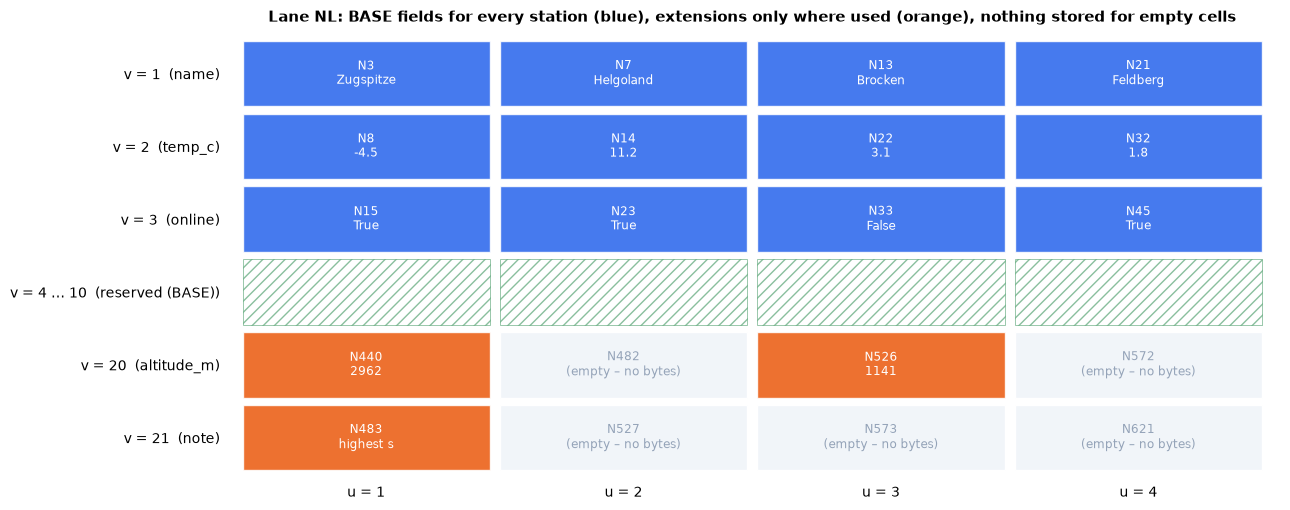

In [6]:
with nhydb.open(PATH) as db:
    shown = {}
    for c in db.iter_materialized_cells(1, lane="NL"):
        shown[(c["u"], c["v"])] = str(c["value"])[:9]

fig, ax = plt.subplots(figsize=(13, 5.2))
rows_v = [1, 2, 3, "4 … 10", 20, 21]
labels = {1: "name", 2: "temp_c", 3: "online", "4 … 10": "reserved (BASE)", 20: "altitude_m", 21: "note"}
for y, v in enumerate(rows_v):
    for u in range(1, 5):
        if v == "4 … 10":
            ax.add_patch(Rectangle((u - 0.48, y - 0.45), 0.96, 0.9, facecolor="white", edgecolor=COLORS["B"],
                                   hatch="///", lw=0.6, alpha=0.5))
            continue
        n = nhydb.dynadron_n(1, u, v, "NL")
        filled = (u, v) in shown
        base = v <= 3
        face = COLORS["NL"] if (filled and base) else (COLORS["attention"] if filled else "#f1f5f9")
        ax.add_patch(Rectangle((u - 0.48, y - 0.45), 0.96, 0.9, facecolor=face, alpha=0.85 if filled else 1,
                               edgecolor="white"))
        txt = f"N{n}\n{shown[(u, v)]}" if filled else f"N{n}\n(empty – no bytes)"
        ax.text(u, y, txt, ha="center", va="center", fontsize=8.5, color="white" if filled else "#94a3b8")
ax.set_yticks(range(len(rows_v)))
ax.set_yticklabels([f"v = {v}  ({labels[v]})" for v in rows_v])
ax.set_xticks(range(1, 5))
ax.set_xticklabels([f"u = {u}" for u in range(1, 5)])
ax.set_xlim(0.45, 4.55)
ax.set_ylim(len(rows_v) - 0.4, -0.6)
ax.set_title("Lane NL: BASE fields for every station (blue), extensions only where used (orange), "
             "nothing stored for empty cells")
for side in ("left", "bottom"):
    ax.spines[side].set_visible(False)
ax.tick_params(length=0)
plt.tight_layout()
plt.show()

**What happened?** The four stations fill `v = 1 … 3` (dense). Only stations 1 and 3 have an
`altitude_m`, and only station 1 has a `note` – the orange cells. Nothing is stored for the empty
cells and for the reserved range `v = 4 … 10`. **Ah – a record is a set of cells, and empty cells cost nothing.**

## 3 · Two lanes: two cells at every `(R, u, v)`

**Question:** What is the second lane for?

**Minimal explanation:** every `(R, u, v)` has two cells: NL (`N = G² − u`) and NR
(`N = G² + v`). They are completely independent – different numbers, different values. An
application can use NR for anything: a second version, metadata, a comment, a measurement in
another unit …

In [7]:
with nhydb.open(PATH) as db:
    db.put_cell(1, 1, 2, "°C, sensor B", type="utf8", lane="NR")          # metadata next to temp_c
    db.put_cell(1, 2, 2, "°C, sensor A", type="utf8", lane="NR", commit=True)
    pairs = []
    for u in (1, 2):
        nl = db.get_value(1, u, 2, lane="NL")
        nr = db.get_value(1, u, 2, lane="NR")
        pairs.append({"station u": u, "v": 2, "NL value": nl, "N (NL)": nhydb.dynadron_n(1, u, 2, "NL"),
                      "NR value": nr, "N (NR)": nhydb.dynadron_n(1, u, 2, "NR")})
pd.DataFrame(pairs).set_index("station u")

,v,NL value,N (NL),NR value,N (NR)
station u,,,,,
1,2,-4.5,8,"°C, sensor B",11
2,2,11.2,14,"°C, sensor A",18


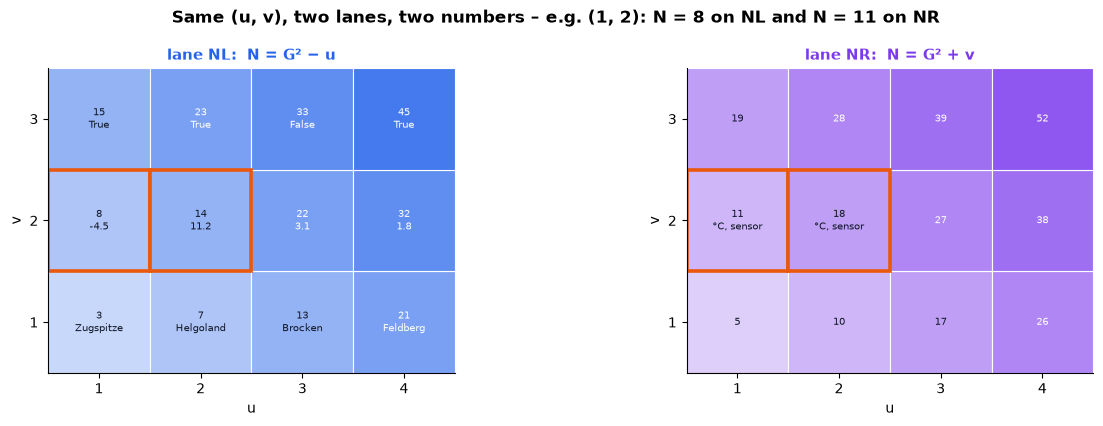

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for ax, lane in zip(axes, ("NL", "NR")):
    with nhydb.open(PATH) as db:
        vals = {(u, v): str(db.get_value(1, u, v, lane=lane))[:10] for u in range(1, 5) for v in (1, 2, 3)
                if db.get_value(1, u, v, lane=lane) is not None}
    plot_address_grid(ax, 4, 3, lane, values=vals, highlight={(1, 2), (2, 2)})
fig.suptitle(f"Same (u, v), two lanes, two numbers – e.g. (1, 2): N = {nhydb.dynadron_n(1, 1, 2, 'NL')} on NL "
             f"and N = {nhydb.dynadron_n(1, 1, 2, 'NR')} on NR", fontweight="bold")
plt.tight_layout()
plt.show()

## 4 · Dense records and sparse cells

**Question:** Why are there two ways to write?

* **Dense:** `put_dense_batch`, `put`, `put_record` write whole records as compact blocks – ideal
  for many records with the same fields.
* **Sparse:** `put_cell`, `put_points` and extensions write single cells with their own address –
  ideal for scattered values. Reading combines both; **the newest write wins**.

▶ **Run it:** the same 2,000 values once as dense records, once as sparse cells.

In [9]:
COUNT = 2000                                     # ▶ Try it: number of values
storage = []
for mode in ("dense", "sparse"):
    p = db_path(f"{mode}.nhydb")
    with nhydb.create(p) as db:
        db.create_realm(1, mode)
        db.create_shape(1, 1, "s", [{"v": 1, "name": "x", "type": "u32"}])
        db.create_classic_layout(1, 1, "c", shape_id=1)
        db.commit()
        start = os.path.getsize(p)
        if mode == "dense":
            db.put_dense_batch(1, 1, [[i] for i in range(COUNT)], commit=True)
        else:
            db.put_points(1, [(u, 1, u - 1, "u32") for u in range(1, COUNT + 1)], commit=True)
        st = db.stats()["storage"]["by_block_type"]
        assert db.get_value(1, COUNT, 1) == COUNT - 1
    storage.append({"mode": mode, "bytes per value": (os.path.getsize(p) - start) / COUNT,
                    "block types": ", ".join(f"{k}×{v['blocks']}" for k, v in st.items() if k.startswith(("DATA", "SPARSE")))})
pd.DataFrame(storage).set_index("mode")

,bytes per value,block types
mode,,
dense,8.024,DATA_DENSE×1
sparse,9.024,SPARSE_CELLS×1


**What happened?** For a regular `u32` field both forms cost about the same per value; the
difference is *how* they are addressed: a dense block covers a run of records with the same fields,
a sparse block lists individual cells with their coordinates. Use dense for tables, sparse for
scattered or optional values – and mix them freely.

## 5 · Null, missing and deleted

**Question:** What is the difference between "no value", "null" and "deleted"?

| State | `get_value` | `get_cell` |
|---|---|---|
| never written | `None` | `None` |
| written as **null** | `None` | present, `value = None` |
| **deleted** (tombstone) | `None` | `None` |

Deleting does not erase bytes – it appends a **new state** (a tombstone). The file is append-only;
`compact_file` removes old states on demand (notebook 11).

In [10]:
PATH_L = db_path("lifecycle.nhydb")
timeline = []
with nhydb.create(PATH_L) as db:
    db.create_realm(1, "life")
    db.commit()

    def snapshot(step):
        cell = db.get_cell(1, 1, 1, dyn_address=False)
        timeline.append({"step": step, "file bytes": os.path.getsize(PATH_L),
                         "get_value": repr(db.get_value(1, 1, 1)),
                         "cell present": cell["present"] if cell else False})

    snapshot("empty")
    db.put_cell(1, 1, 1, "first", type="utf8", commit=True);   snapshot("write 'first'")
    db.put_cell(1, 1, 1, "second", type="utf8", commit=True);  snapshot("overwrite 'second'")
    db.put_cell(1, 1, 1, None, type="utf8", commit=True);      snapshot("write null")
    db.put_cell(1, 1, 1, "third", type="utf8", commit=True);   snapshot("write 'third'")
    db.delete_cell(1, 1, 1, commit=True);                      snapshot("delete")
life = pd.DataFrame(timeline)
life

,step,file bytes,get_value,cell present
0,empty,9128,None,False
1,write 'first',9184,'first',True
2,overwrite 'second',9240,'second',True
3,write null,9288,None,True
4,write 'third',9344,'third',True
5,delete,9392,None,False


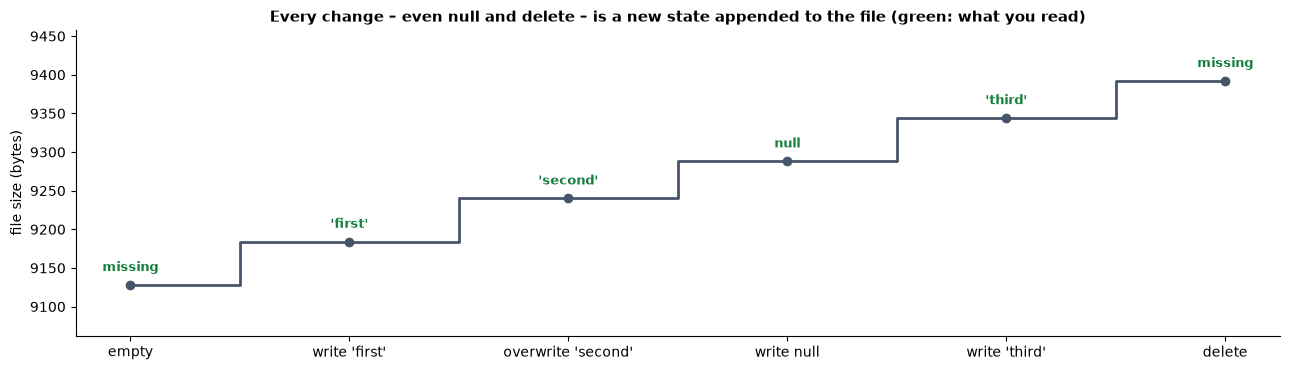

In [11]:
fig, ax = plt.subplots(figsize=(13, 3.8))
x = range(len(life))
ax.step(list(x), life["file bytes"], where="mid", color=COLORS["C"], lw=2)
ax.scatter(list(x), life["file bytes"], color=COLORS["C"], zorder=3)
for xi, row in life.iterrows():
    label = "missing" if not row["cell present"] else ("null" if row["get_value"] == "None" else row["get_value"])
    ax.annotate(label, (xi, row["file bytes"]), textcoords="offset points", xytext=(0, 10), ha="center",
                fontsize=9, color=COLORS["B"], fontweight="bold")
ax.set_xticks(list(x))
ax.set_xticklabels(life["step"])
ax.set_ylabel("file size (bytes)")
ax.set_title("Every change – even null and delete – is a new state appended to the file (green: what you read)")
ax.margins(y=0.25)
plt.tight_layout()
plt.show()
assert list(life["file bytes"]) == sorted(life["file bytes"])
assert life["get_value"].iloc[-1] == "None" and not life["cell present"].iloc[-1]
assert life["get_value"].iloc[3] == "None" and life["cell present"].iloc[3]        # null: present, value None

**What happened?** The file only grows: overwriting, writing null and deleting each append a small
block. Reading always returns the **newest committed state**. **Ah – nothing is lost by accident;
history is only removed when you compact.**

## 6 · Reading many records

**Question:** How do I read a lot of records without loading everything?

`range`, `select` and `select_us` are **lazy iterators**: records are loaded block by block. Gaps
in `u` cost nothing – even a gap of `10^15`.

In [12]:
import itertools

PATH_I = db_path("log.nhydb")
with nhydb.create(PATH_I) as db:
    db.create_realm(1, "log")
    db.create_shape(1, 1, "entry", [{"v": 1, "name": "level", "type": "utf8"},
                                    {"v": 2, "name": "code", "type": "u16"}])
    db.create_classic_layout(1, 1, "log", shape_id=1)
    db.put_dense_batch(1, 1, [["info" if u % 3 else "warn", u] for u in range(1, 1001)])
    db.put(1, 10**15, ["error", 999])                       # far away
    db.commit()

    first = [r["code"] for r in itertools.islice(db.range(1, 1, 10**15), 3)]
    total = sum(1 for _ in db.range(1, 1, 10**15))
    some = list(db.select(1, 998, 1000, ["code"]))
    picked = [r["level"] for r in db.select_us(1, [3, 10**15], ["level"])]
print("first three codes:", first)
print("records between u = 1 and u = 10^15:", total)
print("select 998…1000:", [r["code"] for r in some])
print("select_us [3, 10^15]:", picked)
assert total == 1001 and picked == ["warn", "error"]

first three codes: [1, 2, 3]
records between u = 1 and u = 10^15: 1001
select 998…1000: [998, 999, 1000]
select_us [3, 10^15]: ['warn', 'error']


## 7 · Your turn

**Task:** give station 4 (*Feldberg*) a `note` extension and a comment on the NR lane of its
`name` cell. Then read the record and the NR cell back.

In [13]:
with nhydb.open(PATH) as db:
    db.put_extensions(1, 4, {"note": "Black Forest"})
    db.put_cell(1, 4, 1, "renamed in 2026?", type="utf8", lane="NR", commit=True)
    rec = db.get(1, 4)
    comment = db.get_value(1, 4, 1, lane="NR")
print(rec)
print("NR comment:", comment, "| N of that cell:", nhydb.dynadron_n(1, 4, 1, "NR"))
assert rec["note"] == "Black Forest" and comment == "renamed in 2026?"

{'_realm': 1, '_u': 4, '_lane': 0, '_lane_name': 'NL', '_shape': 1, 'name': 'Feldberg', 'temp_c': 1.8, 'online': True, 'note': 'Black Forest'}
NR comment: renamed in 2026? | N of that cell: 26


## ⏩ Advanced: enums and raw views

A field can map labels to integer codes (`enum`): you write and read labels, the file stores codes.
`get_internal` shows the raw values by `v`.

In [14]:
with nhydb.create(db_path("enum.nhydb")) as db:
    db.create_realm(1, "tickets")
    db.create_shape(1, 1, "ticket", [{"v": 1, "name": "title", "type": "utf8"},
                                     {"v": 2, "name": "state", "type": "u8",
                                      "enum": {"open": 0, "in_progress": 1, "done": 2}}])
    db.create_classic_layout(1, 1, "tickets", shape_id=1)
    db.put_record(1, 1, {"title": "Fix login", "state": "in_progress"}, commit=True)
    print("label:", db.get_record(1, 1)["state"], "| stored code:", db.get_internal(1, 1)["by_v"][2])
    try:
        db.put_record(1, 2, {"title": "x", "state": "unknown"})
    except ValueError as e:
        print("ValueError:", e)

label: in_progress | stored code: in_progress
ValueError: state: unknown enum value 'unknown'


## Summary

* A shape defines typed BASE fields; 15 field types, each written and read back exactly.
* A dense record costs roughly the size of its values plus a few bytes; extensions cost space only where used.
* Every `(R, u, v)` has two independent cells, NL and NR – with different numbers.
* Null, missing and deleted are distinct; every change is a new appended state.
* Lazy iterators read many records and skip gaps of any size.

## Where to go next

* [04 · One Dataset, Different Layouts](04_layouts_side_by_side_v1.ipynb) – other ways to place records.
* [11 · What Actually Lives on Disk?](11_what_lives_on_disk_v1.ipynb) – append-only, commit and compaction.

**Cookbook sections:** 6 (Records), 7 (Single cells, lanes), 8 (Extensions), 11 (Data types), 12 (Iterators) in the [NHyDB Python Cookbook](https://github.com/nhydb/NHyDB/blob/main/docs/cookbook/PYTHON_COOKBOOK.md).

In [15]:
# Clean up: remove the temporary folder with all databases of this notebook.
cleanup()
print("Temporary files removed.")

Temporary files removed.
